# Báo Cáo Thực Nghiệm: Mạng Tích Chập 1D (1D CNN) Hồi Quy Bằng PyTorch
## Bài Toán: Dự Đoán Giá Nhà (Real Estate Continuous Price Regression)
**Học phần:** Phát triển Hệ thống Thông minh (Intelligent System Development)  
**Nhiệm vụ:** Assignment 04 - Triển khai 1D CNN Hồi quy bằng PyTorch (`nn.Conv1d`, Linear Output, MSELoss)  
**Dữ liệu:** `usa_real_estate_150k.csv` (150,000 giao dịch)


In [1]:
import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

device = torch.device('mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu'))
print(f"Thiết bị tính toán: {device}")


Thiết bị tính toán: mps


### 1. Đọc & Tiền Xử Lý Dữ Liệu Đồng Bộ


In [2]:
DATA_PATH = "../../../Assigment 02/house_price/data/usa_real_estate_150k.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "src/Assigment 02/house_price/data/usa_real_estate_150k.csv"

df_raw = pd.read_csv(DATA_PATH)
df_clean = df_raw.dropna(subset=['price', 'house_size', 'bed', 'bath']).copy()
df_clean = df_clean[(df_clean['price'] >= 10000) & (df_clean['price'] <= 5000000)]
df_clean = df_clean[(df_clean['house_size'] >= 200) & (df_clean['house_size'] <= 20000)]

df_clean['log_house_size'] = np.log(df_clean['house_size'])
df_clean['total_rooms'] = df_clean['bed'] + df_clean['bath']
df_clean['bed_bath_prod'] = df_clean['bed'] * df_clean['bath']
df_clean['sqft_per_room'] = df_clean['house_size'] / (df_clean['total_rooms'] + 1)
df_clean['bath_bed_ratio'] = df_clean['bath'] / (df_clean['bed'] + 1)
df_clean['log_acre_lot'] = np.log1p(df_clean['acre_lot'].fillna(df_clean['acre_lot'].median()))
df_clean['log_price'] = np.log(df_clean['price'])

features = ['log_house_size', 'bed', 'bath', 'total_rooms', 'bed_bath_prod', 'sqft_per_room', 'bath_bed_ratio', 'log_acre_lot']

X_data = df_clean[features].values.astype(np.float32)
y_data = df_clean['log_price'].values.astype(np.float32)

X_train_raw, X_test_raw, y_train_log, y_test_log = train_test_split(
    X_data, y_data, test_size=0.20, random_state=RANDOM_SEED
)

scaler_x = StandardScaler()
X_train_scaled = scaler_x.fit_transform(X_train_raw)
X_test_scaled = scaler_x.transform(X_test_raw)

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train_log.reshape(-1, 1)).ravel()
y_test_scaled = scaler_y.transform(y_test_log.reshape(-1, 1)).ravel()

X_train_t = torch.tensor(X_train_scaled[:, np.newaxis, :], dtype=torch.float32)
y_train_t = torch.tensor(y_train_scaled[:, np.newaxis], dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled[:, np.newaxis, :], dtype=torch.float32)
y_test_t = torch.tensor(y_test_scaled[:, np.newaxis], dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=256, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=512, shuffle=False)

print(f"Số lượng mẫu huấn luyện: {len(train_loader.dataset):,} mẫu")


Số lượng mẫu huấn luyện: 120,000 mẫu


### 2. Định Nghĩa Mô Hình 1D CNN PyTorch Cho Hồi Quy
- Đầu ra là 1 nơ-ron tuyến tính: `nn.Linear(16, 1)`.
- Không sử dụng hàm kích hoạt Sigmoid ở tầng cuối.


In [3]:
class HousePriceCNN1D(nn.Module):
    def __init__(self):
        super(HousePriceCNN1D, self).__init__()
        self.network = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=16, kernel_size=3),
            nn.ReLU(),
            nn.Conv1d(in_channels=16, out_channels=32, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            nn.Flatten(),
            nn.Linear(32 * 2, 16),
            nn.ReLU(),
            nn.Linear(16, 1) # Nơ-ron tuyến tính thuần túy
        )

    def forward(self, x):
        return self.network(x)

model = HousePriceCNN1D().to(device)
print(model)


HousePriceCNN1D(
  (network): Sequential(
    (0): Conv1d(1, 16, kernel_size=(3,), stride=(1,))
    (1): ReLU()
    (2): Conv1d(16, 32, kernel_size=(3,), stride=(1,))
    (3): ReLU()
    (4): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Flatten(start_dim=1, end_dim=-1)
    (6): Linear(in_features=64, out_features=16, bias=True)
    (7): ReLU()
    (8): Linear(in_features=16, out_features=1, bias=True)
  )
)


### 3. Huấn Luyện Mô Hình Với PyTorch


In [4]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.002)
epochs = 12

history = {"loss": [], "val_loss": [], "val_r2": []}

start_time = time.time()
print("Bắt đầu huấn luyện mô hình 1D CNN Hồi quy PyTorch...")

for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * len(batch_y)
        
    epoch_loss = running_loss / len(train_loader.dataset)
    
    model.eval()
    val_loss = 0.0
    all_preds = []
    with torch.no_grad():
        for val_x, val_y in test_loader:
            val_x, val_y = val_x.to(device), val_y.to(device)
            preds = model(val_x)
            v_loss = criterion(preds, val_y)
            val_loss += v_loss.item() * len(val_y)
            all_preds.extend(preds.cpu().numpy().ravel())
            
    val_loss = val_loss / len(test_loader.dataset)
    val_r2 = r2_score(y_test_scaled, np.array(all_preds))
    
    history["loss"].append(epoch_loss)
    history["val_loss"].append(val_loss)
    history["val_r2"].append(val_r2)
    
    print(f"Epoch {epoch:02d}/{epochs:02d} - Train MSE: {epoch_loss:.4f} | Val MSE: {val_loss:.4f} | Val R²: {val_r2:.4f}")

train_time = time.time() - start_time
print(f"\nHuấn luyện PyTorch hoàn tất trong: {train_time:.2f} giây!")


Bắt đầu huấn luyện mô hình 1D CNN Hồi quy PyTorch...


Epoch 01/12 - Train MSE: 0.6455 | Val MSE: 0.6295 | Val R²: 0.3716


Epoch 02/12 - Train MSE: 0.6222 | Val MSE: 0.6247 | Val R²: 0.3763


Epoch 03/12 - Train MSE: 0.6194 | Val MSE: 0.6233 | Val R²: 0.3777


Epoch 04/12 - Train MSE: 0.6160 | Val MSE: 0.6203 | Val R²: 0.3807


Epoch 05/12 - Train MSE: 0.6106 | Val MSE: 0.6171 | Val R²: 0.3840


... (3 outputs left out)

Epoch 09/12 - Train MSE: 0.5973 | Val MSE: 0.6055 | Val R²: 0.3955


Epoch 10/12 - Train MSE: 0.5962 | Val MSE: 0.6080 | Val R²: 0.3930


Epoch 11/12 - Train MSE: 0.5953 | Val MSE: 0.6013 | Val R²: 0.3997


Epoch 12/12 - Train MSE: 0.5944 | Val MSE: 0.6011 | Val R²: 0.3999

Huấn luyện PyTorch hoàn tất trong: 41.48 giây!


### 4. Đánh Giá Toàn Diện & Trực Quan Hóa Kết Quả


=== KẾT QUẢ ĐÁNH GIÁ 1D CNN HỒI QUY (PYTORCH) ===
• R² Score (Log space)  : 0.3999
• RMSE (Log space)      : 0.6841
• MAE (Log space)       : 0.5184
• MAE (Thực tế USD)     : $290,404.47
• Thời gian huấn luyện  : 41.48 giây


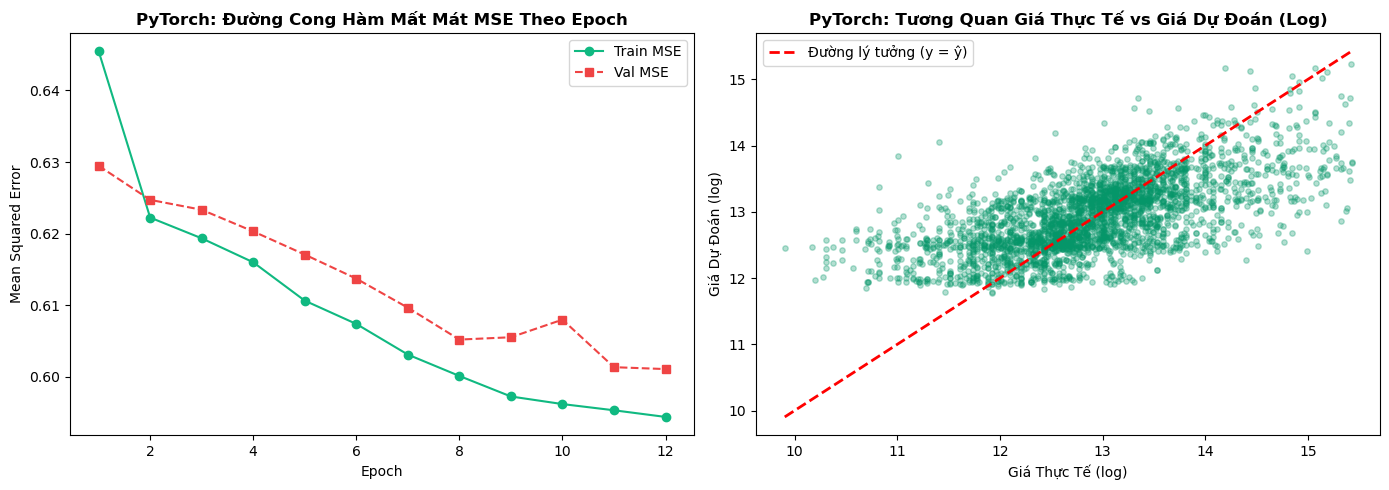

In [5]:
model.eval()
with torch.no_grad():
    val_preds_scaled = model(X_test_t.to(device)).cpu().numpy().ravel()
val_preds_log = scaler_y.inverse_transform(val_preds_scaled.reshape(-1, 1)).ravel()

r2_val = r2_score(y_test_log, val_preds_log)
rmse_log = np.sqrt(mean_squared_error(y_test_log, val_preds_log))
mae_log = mean_absolute_error(y_test_log, val_preds_log)

y_test_dollars = np.exp(y_test_log)
preds_dollars = np.exp(val_preds_log)
mae_dollars = mean_absolute_error(y_test_dollars, preds_dollars)
rmse_dollars = np.sqrt(mean_squared_error(y_test_dollars, preds_dollars))

print(f"=== KẾT QUẢ ĐÁNH GIÁ 1D CNN HỒI QUY (PYTORCH) ===")
print(f"• R² Score (Log space)  : {r2_val:.4f}")
print(f"• RMSE (Log space)      : {rmse_log:.4f}")
print(f"• MAE (Log space)       : {mae_log:.4f}")
print(f"• MAE (Thực tế USD)     : ${mae_dollars:,.2f}")
print(f"• Thời gian huấn luyện  : {train_time:.2f} giây")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, epochs + 1), history["loss"], 'o-', color='#10b981', label='Train MSE')
axes[0].plot(range(1, epochs + 1), history["val_loss"], 's--', color='#ef4444', label='Val MSE')
axes[0].set_title('PyTorch: Đường Cong Hàm Mất Mát MSE Theo Epoch', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Mean Squared Error')
axes[0].legend()

sample_idx = np.random.choice(len(y_test_log), size=3000, replace=False)
axes[1].scatter(np.asarray(y_test_log)[sample_idx], val_preds_log[sample_idx], alpha=0.3, color='#059669', s=15)
min_val = min(y_test_log.min(), val_preds_log.min())
max_val = max(y_test_log.max(), val_preds_log.max())
axes[1].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Đường lý tưởng (y = ŷ)')
axes[1].set_title('PyTorch: Tương Quan Giá Thực Tế vs Giá Dự Đoán (Log)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Giá Thực Tế (log)')
axes[1].set_ylabel('Giá Dự Đoán (log)')
axes[1].legend()

plt.tight_layout()
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/02_house_price_pytorch_results.png", dpi=300)
plt.show()


### 5. Lưu Trữ Kết Quả Thực Nghiệm


In [6]:
results_df = pd.DataFrame([{
    "Framework": "PyTorch",
    "Dataset": "House Price (150k)",
    "R2_Score": r2_val,
    "RMSE_Log": rmse_log,
    "MAE_Log": mae_log,
    "MAE_Dollars": mae_dollars,
    "Train_Time_Sec": train_time,
    "Epochs": epochs,
    "Batch_Size": 256
}])

results_df.to_csv("../reports/model_results_pytorch.csv", index=False)
print("Đã lưu kết quả thành công vào ../reports/model_results_pytorch.csv")
results_df


Đã lưu kết quả thành công vào ../reports/model_results_pytorch.csv


,Framework,Dataset,R2_Score,RMSE_Log,MAE_Log,MAE_Dollars,Train_Time_Sec,Epochs,Batch_Size
0,PyTorch,House Price (150k),0.399917,0.684117,0.518442,290404.46875,41.479366,12,256
